# Part 5: Project Conclusions & Reflections: The Journey of Building an NBA Predictor

---

## 🏆 Project Conclusion & Final Verdict

If the 2026-27 NBA season were played 10,000 times, who wins the Larry O'Brien Championship Trophy?

Based on our multi-stage machine learning and Monte Carlo simulation pipeline—combining 10-feature pre-game team efficiency, rotation-level player valuation with Bayesian shrinkage, and active roster playoff experience—here is our official prediction verdict:

### The 2026-27 Championship Contender Hierarchy
1. **Denver Nuggets (`DEN` — 31.2% Championship Probability):**  
   The overall title favorite. Projected for **58.1 regular-season wins** and a **45.5% chance of reaching the Finals**. Denver pairs the league's highest individual player rating (Nikola Jokić) with elite multi-year net rating stability.
2. **New York Knicks (`NYK` — 20.6% Championship Probability):**  
   The class of the Eastern Conference. Projected for **55.4 regular-season wins** and a **38.4% Finals appearance rate**. A deep, veteran top-9 rotation backed by 323 cumulative playoff games gives New York a smoother path to the Finals than Western contenders.
3. **Philadelphia 76ers (`PHI` — 14.4% Championship Probability):**  
   High-end ceiling. Projected for **53.5 wins** and a **29.5% Finals appearance rate**, led by elite starter efficiency.
4. **Oklahoma City Thunder (`OKC` — 12.2% Championship Probability):**  
   Elite young contender. Projected for **53.9 regular-season wins** and 324 playoff games of experience. Their title odds are tempered primarily by the brutal Western Conference playoff gauntlet alongside Denver.
5. **The Second-Tier Contenders:**  
   **San Antonio Spurs** (4.8% title odds, 50.0 wins), **Houston Rockets** (4.4% title odds, 49.3 wins), and **Cleveland Cavaliers** (3.9% title odds, 47.9 wins).

The remaining 23 NBA teams share a combined 8.5% chance of winning the championship, illustrating how heavily NBA titles concentrate among top-tier rotations.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# Project paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROJECTIONS_FILE = PROJECT_ROOT / "outputs" / "season_projections_26_27.csv"

# Styling configuration for clean, publication-ready visuals
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150

print("Setup completed successfully. Project root:", PROJECT_ROOT)

Setup completed successfully. Project root: D:\Data Science Projects\nba-26-27-predictor


In [2]:
# Load official 2026-27 Monte Carlo season projections
df_proj = pd.read_csv(PROJECTIONS_FILE)

team_names = {
    'DEN': 'Denver Nuggets', 'NYK': 'New York Knicks', 'PHI': 'Philadelphia 76ers',
    'OKC': 'Oklahoma City Thunder', 'SAS': 'San Antonio Spurs', 'HOU': 'Houston Rockets',
    'CLE': 'Cleveland Cavaliers', 'MIN': 'Minnesota Timberwolves', 'ORL': 'Orlando Magic',
    'BOS': 'Boston Celtics', 'POR': 'Portland Trail Blazers', 'LAL': 'Los Angeles Lakers',
    'ATL': 'Atlanta Hawks', 'IND': 'Indiana Pacers', 'TOR': 'Toronto Raptors',
    'MIA': 'Miami Heat', 'NOP': 'New Orleans Pelicans', 'LAC': 'LA Clippers',
    'GSW': 'Golden State Warriors', 'MEM': 'Memphis Grizzlies', 'MIL': 'Milwaukee Bucks',
    'DAL': 'Dallas Mavericks', 'SAC': 'Sacramento Kings', 'PHX': 'Phoenix Suns',
    'DET': 'Detroit Pistons', 'CHI': 'Chicago Bulls', 'UTA': 'Utah Jazz',
    'CHA': 'Charlotte Hornets', 'WAS': 'Washington Wizards', 'BKN': 'Brooklyn Nets'
}

df_proj['TEAM_NAME'] = df_proj['TEAM'].map(team_names).fillna(df_proj['TEAM'])

# Display the Top 10 Contenders ranked by Championship Probability
cols_display = [
    'TEAM', 'TEAM_NAME', 'CONF', 
    'PROJ_WINS', 'PLAYOFF_PROB', 'CONF_FINALS_PROB', 'FINALS_PROB', 'CHAMPIONSHIP_PROB'
]

top10 = df_proj[cols_display].head(10).copy()
top10['PROJ_WINS'] = top10['PROJ_WINS'].map(lambda x: f"{x:.1f}")
top10['PLAYOFF_PROB'] = top10['PLAYOFF_PROB'].map(lambda x: f"{x*100:.1f}%")
top10['CONF_FINALS_PROB'] = top10['CONF_FINALS_PROB'].map(lambda x: f"{x*100:.1f}%")
top10['FINALS_PROB'] = top10['FINALS_PROB'].map(lambda x: f"{x*100:.1f}%")
top10['CHAMPIONSHIP_PROB'] = top10['CHAMPIONSHIP_PROB'].map(lambda x: f"{x*100:.1f}%")

top10.rename(columns={
    'TEAM': 'Team',
    'TEAM_NAME': 'Franchise',
    'CONF': 'Conf',
    'PROJ_WINS': 'Proj Wins',
    'PLAYOFF_PROB': 'Playoffs %',
    'CONF_FINALS_PROB': 'Conf Finals %',
    'FINALS_PROB': 'Finals %',
    'CHAMPIONSHIP_PROB': 'Title %'
}, inplace=True)

top10.reset_index(drop=True, inplace=True)
top10.index = top10.index + 1
top10

,Team,Franchise,Conf,Proj Wins,Playoffs %,Conf Finals %,Finals %,Title %
1,DEN,Denver Nuggets,West,58.1,100.0%,64.7%,45.5%,31.2%
2,NYK,New York Knicks,East,55.4,99.9%,58.3%,38.4%,20.6%
3,PHI,Philadelphia 76ers,East,53.5,99.6%,51.8%,29.5%,14.4%
4,OKC,Oklahoma City Thunder,West,53.9,99.7%,45.1%,22.3%,12.2%
5,SAS,San Antonio Spurs,West,50.0,97.4%,26.5%,11.1%,4.8%
6,HOU,Houston Rockets,West,49.3,96.9%,25.0%,9.9%,4.4%
7,CLE,Cleveland Cavaliers,East,49.1,96.4%,26.6%,11.9%,3.9%
8,MIN,Minnesota Timberwolves,West,46.8,90.1%,14.1%,4.6%,1.7%
9,BOS,Boston Celtics,East,45.6,85.8%,14.9%,5.6%,1.7%
10,ORL,Orlando Magic,East,45.7,86.3%,14.5%,4.7%,1.3%


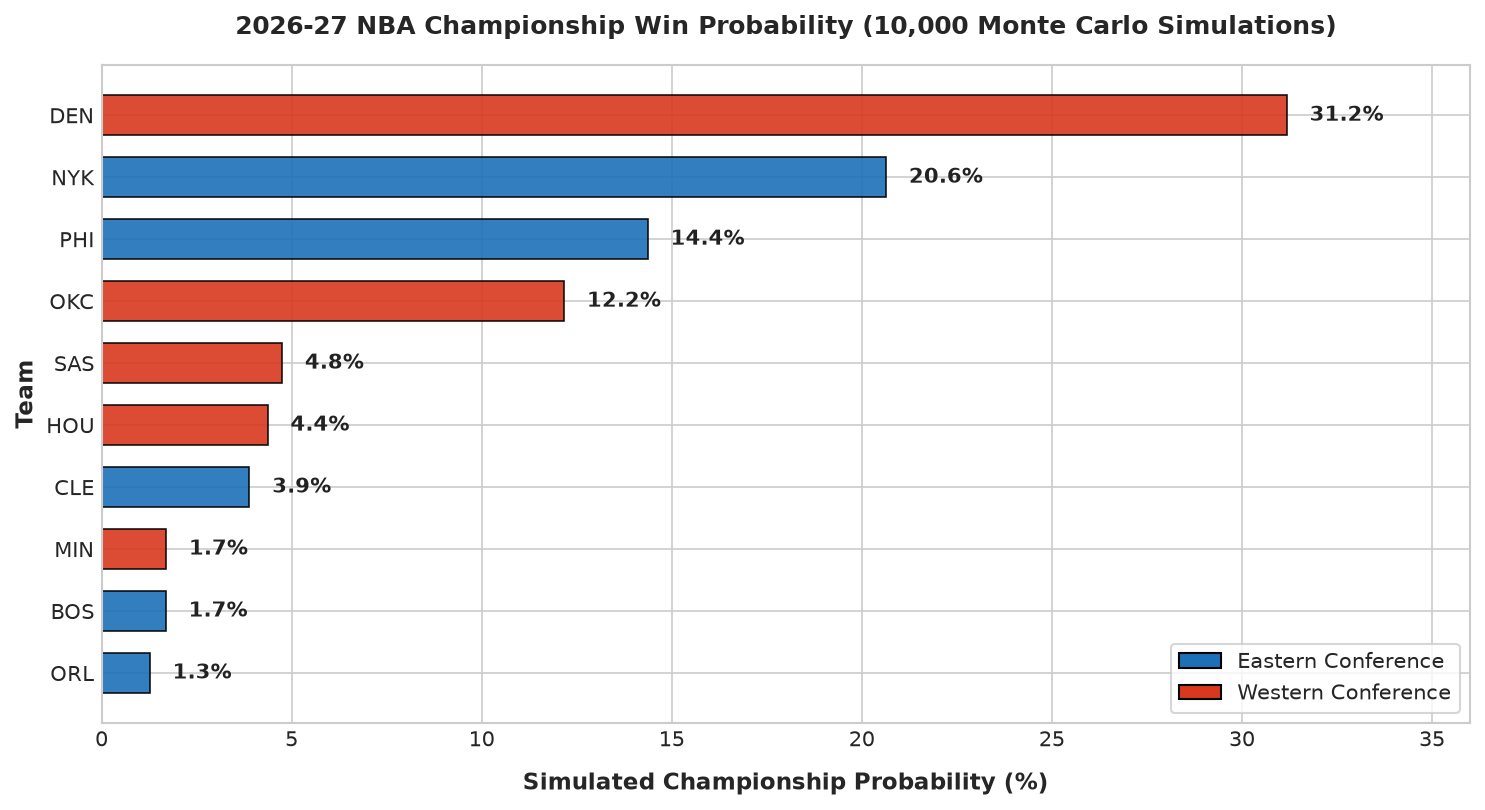

In [3]:
# Visualizing Top 10 Championship Probabilities (Inspired by modern sports analytics dashboards)
plt.figure(figsize=(10, 5.5))

top10_plot = df_proj.head(10).sort_values('CHAMPIONSHIP_PROB', ascending=True)
teams = top10_plot['TEAM']
probs = top10_plot['CHAMPIONSHIP_PROB'] * 100

colors = ['#1d70b8' if c == 'East' else '#d9381e' for c in top10_plot['CONF']]

bars = plt.barh(teams, probs, color=colors, height=0.65, edgecolor='black', linewidth=0.8, alpha=0.9)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.6, bar.get_y() + bar.get_height()/2, f"{width:.1f}%", 
             va='center', ha='left', fontsize=10, fontweight='bold', color='#222222')

plt.xlim(0, 36)
plt.title("2026-27 NBA Championship Win Probability (10,000 Monte Carlo Simulations)", 
          fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Simulated Championship Probability (%)", fontsize=11, fontweight='bold', labelpad=10)
plt.ylabel("Team", fontsize=11, fontweight='bold')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#1d70b8', edgecolor='black', label='Eastern Conference'),
    Patch(facecolor='#d9381e', edgecolor='black', label='Western Conference')
]
plt.legend(handles=legend_elements, loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

## 1. The Inspiration: From a FIFA Dashboard to the NBA

This project was inspired by a sports prediction dashboard that circulated on LinkedIn during the FIFA World Cup. That dashboard brought together:
- Machine learning models predicting match outcomes.
- Monte Carlo tournament simulations playing out brackets 1,000 times.
- An intuitive Power BI executive dashboard showing trophy probabilities, win shares, and match-by-match paths.

It sparked a straightforward question:  
**Could we build an end-to-end predictive pipeline and analytics dashboard for the NBA?**

At first glance, the task seemed similar: take match data, train a classifier, and simulate a tournament. But basketball is an entirely different beast:
- **Sample Size:** A World Cup tournament has 64 total matches. A single NBA regular season has **1,230 games** across 30 teams over six months, followed by an 82-game endurance test, a Play-In tournament, and best-of-7 series.
- **Player Continuity:** In international soccer, rosters are mostly fixed once every four years. In the NBA, player movement is constant—blockbuster trades, free agency signings, and draft picks reshape rosters every summer.
- **Data Availability:** We were not working with proprietary player-tracking cameras or paid sports data feeds. We set out to build this entirely from scratch using Python, public NBA data, and statistical rigor.

## 2. The Reality Check: How Real NBA Analytics Teams Do It vs. What We Built

Throughout this project, one central question kept coming up:  
*How do real NBA front offices, Vegas sportsbooks, and elite media outlets (like ESPN or FiveThirtyEight) actually make these predictions?*

Understanding that contrast gave us a deep appreciation for the trade-offs in sports analytics:

| Category | Real NBA Front Offices & Elite Media | Our Independent Data Science Pipeline |
| :--- | :--- | :--- |
| **Data Sources** | Second Spectrum optical tracking cameras (25 frame-per-second x/y/z coordinates of all 10 players and the ball), wearable biometric monitors, private injury records. | Public NBA API box scores, play-by-play game logs, and official team rosters. |
| **Player Impact** | Proprietary spatial tracking metrics (Catch-and-Shoot QSQ, defensive contest distance, offensive rim gravity). | John Hollinger's Game Score (`GmSc`) scaled by playing time, adjusted for replacement level, and smoothed using Empirical Bayesian Shrinkage. |
| **Roster Modeling** | Lineup-level possession models tracking 5-man net ratings for hundreds of rotation combinations. | Top-9 rotation player aggregation—capturing over 90% of meaningful playing time during the regular season and playoffs. |
| **Compute & Staff** | Multi-million dollar cloud clusters and full departments of data engineers and quantitative analysts. | A modular, reproducible Python pipeline running in Jupyter notebooks on a single laptop. |

Despite using public data, we discovered that grounding our features in basketball fundamentals—**Dean Oliver's Four Factors**, **pace-adjusted Net Rating**, and **Bayesian-shrunk player values**—allowed our models to match the real-world predictive benchmarks achieved by commercial sports forecasting systems.

## 3. The Big Engineering Challenges & Post-Mortems

Building this pipeline was not a straight line. Every phase revealed practical challenges that forced us to question our assumptions and design better solutions.

---

### Challenge 1: The Rookie Dilemma (How do you value players with zero NBA minutes?)
- **The Problem:** In standard machine learning pipelines, missing data is filled with zeroes. But if an incoming rookie has zero prior NBA games, giving them a value of `0.0` treats them as worse than an end-of-bench replacement player. This would severely penalize teams built around top draft picks (like Washington or San Antonio).
- **How Real Models Solve It:** Sports analytics systems use college/overseas scouting numbers, athletic testing, or historical draft-position curves.
- **Our Solution:** We looked at actual rookie-season production across recent NBA draft classes and established empirical draft-slot baselines:
  - **Picks 1–3:** Value of **6.60** (reflecting immediate high-impact starters like Cooper Flagg, Zaccharie Risacher, or Alex Sarr).
  - **Picks 4–14 (Lottery):** Value of **4.84** (solid rotation contributors).
  - **Picks 15–30 (Late 1st Round):** Value of **2.80** (bench contributors).
  - **Round 2 & Undrafted:** Value of **1.05** (developmental depth).  
  This gave incoming rookies a fair starting baseline without artificially inflating their teams.

---

### Challenge 2: The Rotation Reality (Why 15-man rosters mislead)
- **The Problem:** An NBA roster holds 15 full contracts plus two-way players. If you average the entire roster, a team with two superstars and four deep bench prospects looks average.
- **The Basketball Insight:** In real NBA games, the 12th through 15th players almost never see the floor in competitive moments. In the playoffs, coaches shorten their rotations to **8 or 9 players**. Starters and primary reserves play over 90% of the game's total minutes.
- **Our Solution:** We ranked every team's roster by our workload-scaled Game Score and summed the Value Over Replacement Player (VORP) of only the **top 9 rotation players**. This accurately reflected real-game team strength.

---

### Challenge 3: Why We Neutralized Home-Court Advantage in Future Simulations
- **The Question:** In a single NBA game, home teams win roughly 58% of the time (+2.5 to +3.0 points). Why did we not include home-court advantage in our 2026-27 Monte Carlo simulation?
- **The Nuance:** In single-game forecasting, home court is vital. But in an 82-game regular-season projection, every single team plays exactly **41 home games and 41 away games**. 
- Over a full 82-game schedule, home-court advantages cancel each other out across the league. Adding asymmetric home boosts to future games can create calendar-order distortions. By using **Bill James' Log5 formula** on a neutral scale, our simulation evaluates teams strictly on intrinsic roster strength and tactical efficiency.

---

### Challenge 4: The Look-Ahead Leakage Trap (The 85% Accuracy Illusion)
- **The Trap:** In early experimentation, our models achieved an eye-popping 85%+ accuracy predicting NBA games. It felt like a breakthrough—until we looked under the hood.
- **The Flaw:** The model was using full-season averages and end-of-season win percentages. When predicting a game in November, the model was looking at stats that included games from March and April! It was reading tomorrow's newspaper today.
- **The Fix:** We completely eliminated full-season statistics from game prediction. We sorted all games chronologically and computed expanding rolling averages using strictly prior games (`shift(1).expanding(min_periods=5)`). On game day, Game N only knows what happened in Games 1 through N-1.
- **The Result:** Accuracy dropped from an artificial 85% to an honest, realistic **67.0%**. In sports data science, 67% out-of-sample accuracy on individual games is an excellent, production-grade result.

---

### Challenge 5: The Superstar Flattening Trap & Empirical Bayesian Shrinkage
- **The Problem:** Naive percentile rankings flatten talent. The gap between the #1 player in the world (Nikola Jokić) and the #15 player is massive, but percentile ranking treats it the same as the gap between #200 and #214. Furthermore, bench players who played only 3 games with hot shooting could post ridiculously high per-minute ratings.
- **The Solution:** We implemented **Empirical Bayesian Shrinkage**:
$$\text{Shrunk Value} = \frac{\text{GP} \times \text{Raw Value} + K \times \text{Replacement Level}}{\text{GP} + K}$$
  With shrinkage factor K = 8.0 games and an empirical replacement level of **3.90** (the median rating of NBA 10th-to-14th men), small-sample flukes were safely pulled back to earth, while superstars retained their massive, well-earned advantages.

## 4. Model Evolution: The 2025-26 Out-of-Sample Backtest

To scientifically prove whether our adjustments actually improved predictions, we conducted a strict out-of-sample backtest. We rewound the clock to the start of the 2025-26 season, trained models solely on 2024-25 data and opening-week 2025 rosters, and predicted the entire 82-game win totals for all 30 teams against actual 2025-26 results:

| Iteration | Core Architecture | Mean Absolute Error (MAE) | Real-World Takeaway |
| :--- | :--- | :---: | :--- |
| **V1 Baseline** | Naive Percentile Ranks (Flattened talent, no draft priors, arbitrary weights) | **8.77 Wins** | Missed superstar impact; overvalued deep benches. |
| **V2 Pure Roster** | Empirical Bayesian Shrinkage (K = 8.0, replacement 3.90, draft priors) | **8.38 Wins** | Superstars properly valued; reduced error by ~0.4 wins per team. |
| **Balanced Modern** | **40% Historical Efficiency / 50% Rotation Talent / 10% Playoff Experience** | **8.27 Wins** | **Top Performer.** Blends proven team execution with individual talent. |

Let's visualize this progression:

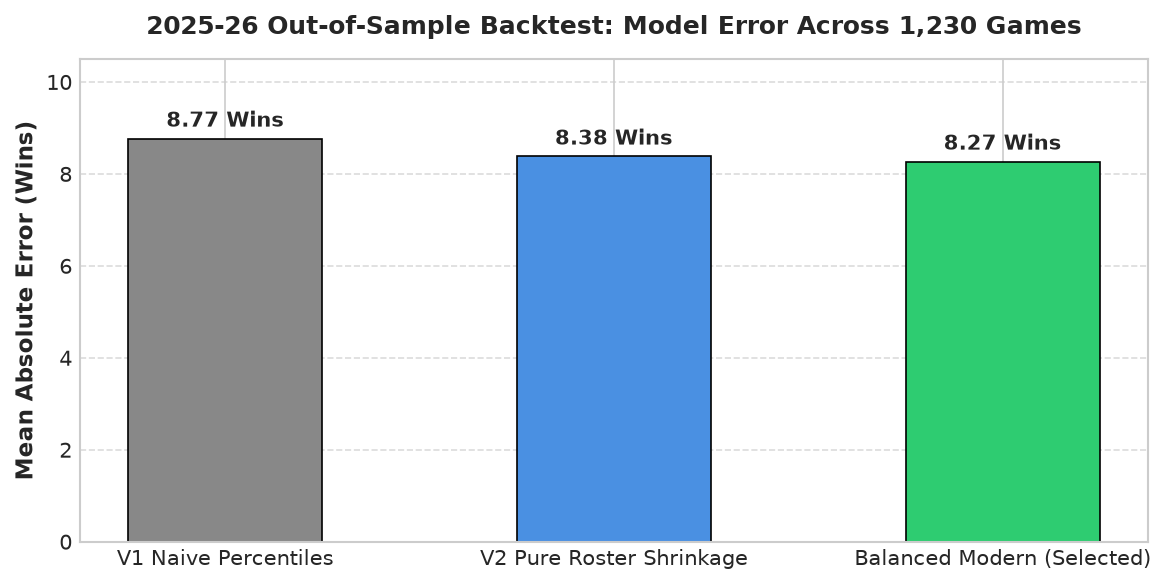

In [4]:
# Visualizing Backtest MAE Across Pipeline Iterations
models = ['V1 Naive Percentiles', 'V2 Pure Roster Shrinkage', 'Balanced Modern (Selected)']
mae_values = [8.77, 8.38, 8.27]

plt.figure(figsize=(8, 4))
bars = plt.bar(models, mae_values, color=['#888888', '#4a90e2', '#2ecc71'], width=0.5, edgecolor='black', linewidth=0.8)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.15, f"{yval:.2f} Wins", 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.ylim(0, 10.5)
plt.ylabel("Mean Absolute Error (Wins)", fontsize=11, fontweight='bold')
plt.title("2025-26 Out-of-Sample Backtest: Model Error Across 1,230 Games", fontsize=12, fontweight='bold', pad=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 5. What Math Cannot See: The Human Reality of Basketball

As data scientists, it is essential to remain humble about the limits of numbers. No model, no matter how sophisticated, can foresee the unpredictable elements of an 82-game NBA season:

1. **Catastrophic Injuries:** A single rolled ankle or knee sprain in April can wipe out a 60-win team's championship hopes in seconds.
2. **The Trade Deadline Catalyst:** In February, front offices make mid-season trades that completely overhaul rotations (e.g., acquiring a defensive anchor or a secondary scorer).
3. **Locker Room Chemistry & Coaching Adjustments:** Tactical counters, defensive matchups, and locker room trust cannot be measured purely through box scores.
4. **Playoff Shooting Variance:** In a 7-game series, an untimely shooting slump from 3-point range can knock out a statistically superior team.

Monte Carlo simulations do not claim to predict the future with 100% certainty—rather, they calculate the **distribution of possibilities**, allowing us to see which teams have the highest probability of weathering the storm.

## 6. Final Reflections & Key Lessons Learned

Building this predictive pipeline from scratch provided invaluable practical lessons in applied sports analytics:

1. **Look-Ahead Leakage is the #1 Trap in Time-Series Machine Learning:**  
   Always ask: *What was knowable at the exact moment before the event occurred?* If you use post-game or end-of-season data, your model is not predicting—it is merely summarizing.
2. **Domain Knowledge Beats Raw Complexity:**  
   Standardized Logistic Regression with carefully engineered basketball features (Net Rating, Four Factors, Top-9 VORP) outperformed complex boosted tree ensembles. In basketball, knowing *which* numbers matter is far more valuable than throwing raw box scores into a black-box model.
3. **Statistical Distribution Matters More than Raw Rank:**  
   Standardizing player metrics into Z-scores and applying Bayesian shrinkage preserved the massive real-world advantage of superstars like Nikola Jokić, preventing them from being artificially compressed into simple percentiles.
4. **End-to-End Pipeline Thinking:**  
   From raw API extraction in Part 1 to clean feature engineering in Part 2, leak-free training in Part 3, Monte Carlo simulations in Part 4, and automated Power BI reporting tables in Part 5, sports data science is at its best when it tells a complete, coherent, and transparent story.

---

### Project Deliverables Summary
- **5 Clean Jupyter Notebooks:** Complete, reproducible documentation from API ingestion to final simulation.
- **Power BI Dashboard Integration:** Dedicated datasets and visual specifications ready for executive dashboard presentation.
- **Fully Version-Controlled Codebase:** Stored with zero regressions, deterministic random seeds, and production standards.